In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


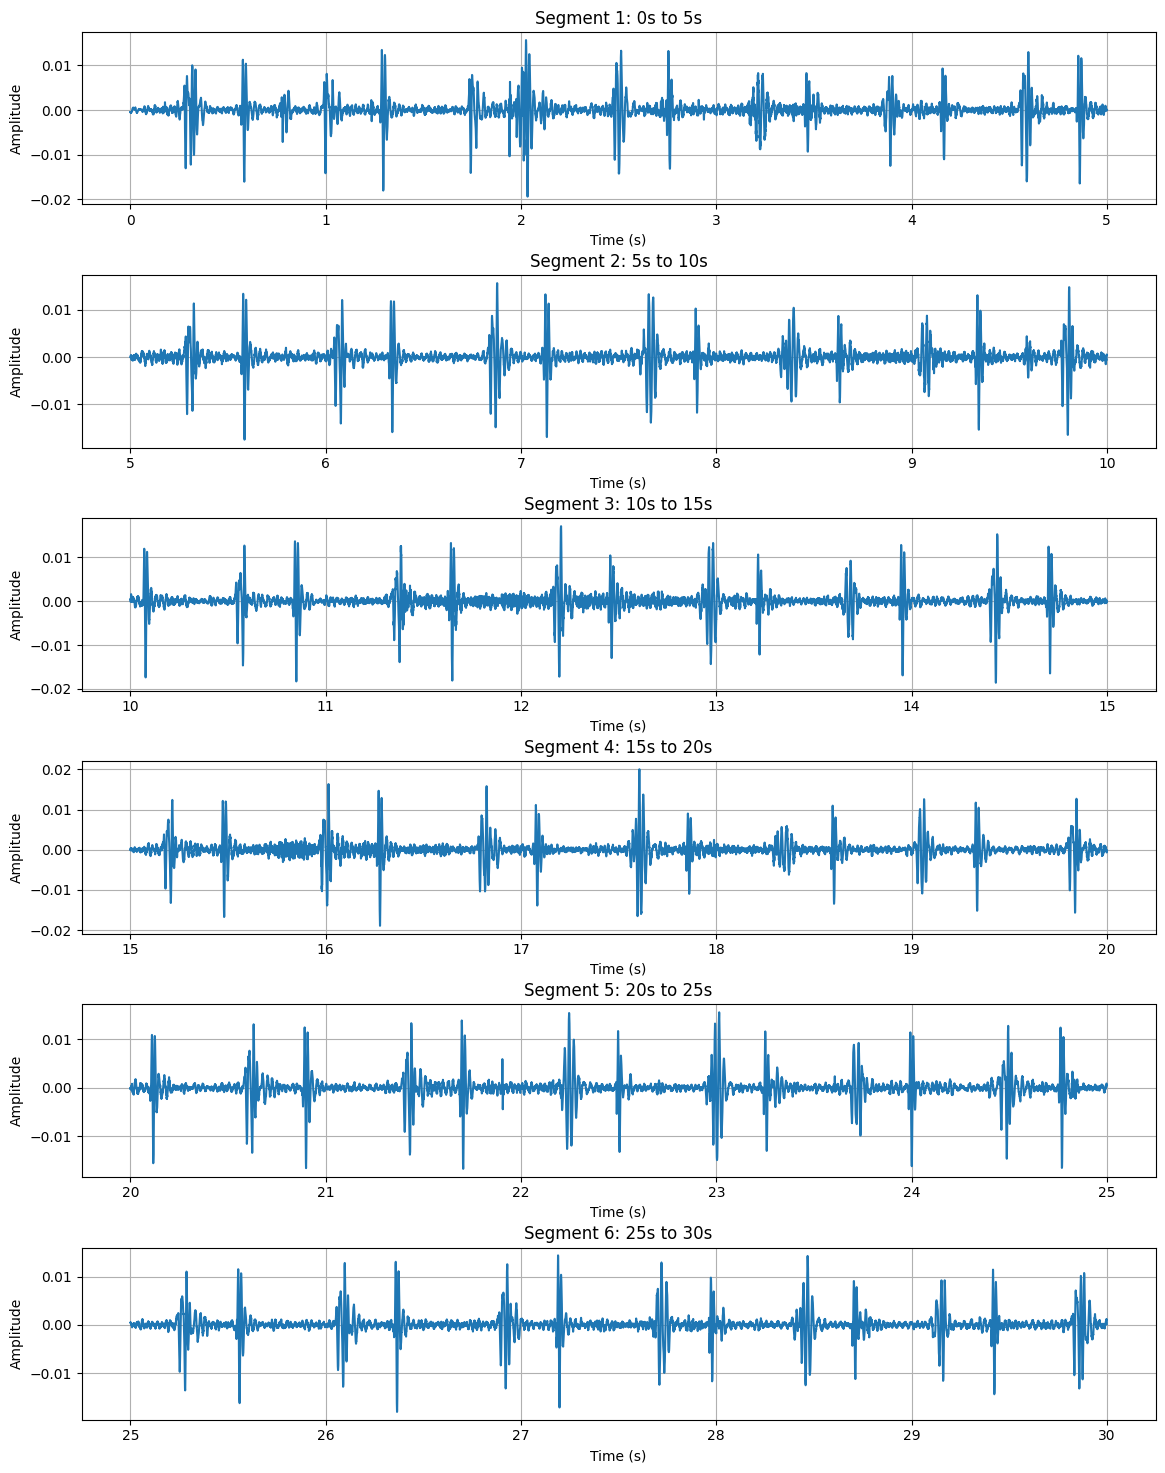

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Path to the audio file
file_path = '/content/drive/MyDrive/Research 2026/Data/Normal/Copy of Apex.wav'

# Load the audio file
y, sr = librosa.load(file_path)
duration = librosa.get_duration(y=y, sr=sr)

# Settings for segments
segment_duration = 5
num_segments = 6

fig, axes = plt.subplots(num_segments, 1, figsize=(12, 15), sharex=False)
fig.tight_layout(pad=3.0)

for i in range(num_segments):
    start_time = i * segment_duration
    if start_time >= duration:
        axes[i].set_visible(False)
        continue

    end_time = min((i + 1) * segment_duration, duration)

    # Slice the audio array
    start_sample = int(start_time * sr)
    end_sample = int(end_time * sr)
    y_segment = y[start_sample:end_sample]
    t_segment = np.linspace(start_time, end_time, len(y_segment))

    axes[i].plot(t_segment, y_segment)
    axes[i].set_title(f'Segment {i+1}: {start_time}s to {end_time}s')
    axes[i].set_xlabel('Time (s)')
    axes[i].set_ylabel('Amplitude')
    axes[i].grid(True)

plt.show()

In [ ]:
import os
import soundfile as sf

# Create the output directory
output_dir = '/content/normal_segment'
os.makedirs(output_dir, exist_ok=True)

# Base name for the audio file
base_name = "Copy of Apex"

# Loop through segments and save them
for i in range(num_segments):
    start_time = i * segment_duration
    if start_time >= duration:
        break

    end_time = min((i + 1) * segment_duration, duration)

    # Slice the audio array
    start_sample = int(start_time * sr)
    end_sample = int(end_time * sr)
    y_segment = y[start_sample:end_sample]

    # Define the output file name
    output_filename = f"{base_name}_{i+1}.wav"
    output_path = os.path.join(output_dir, output_filename)

    # Save the segment
    sf.write(output_path, y_segment, sr)
    print(f"Saved: {output_path}")

Saved: /content/normal_segment/Copy of Apex_1.wav
Saved: /content/normal_segment/Copy of Apex_2.wav
Saved: /content/normal_segment/Copy of Apex_3.wav
Saved: /content/normal_segment/Copy of Apex_4.wav
Saved: /content/normal_segment/Copy of Apex_5.wav
Saved: /content/normal_segment/Copy of Apex_6.wav


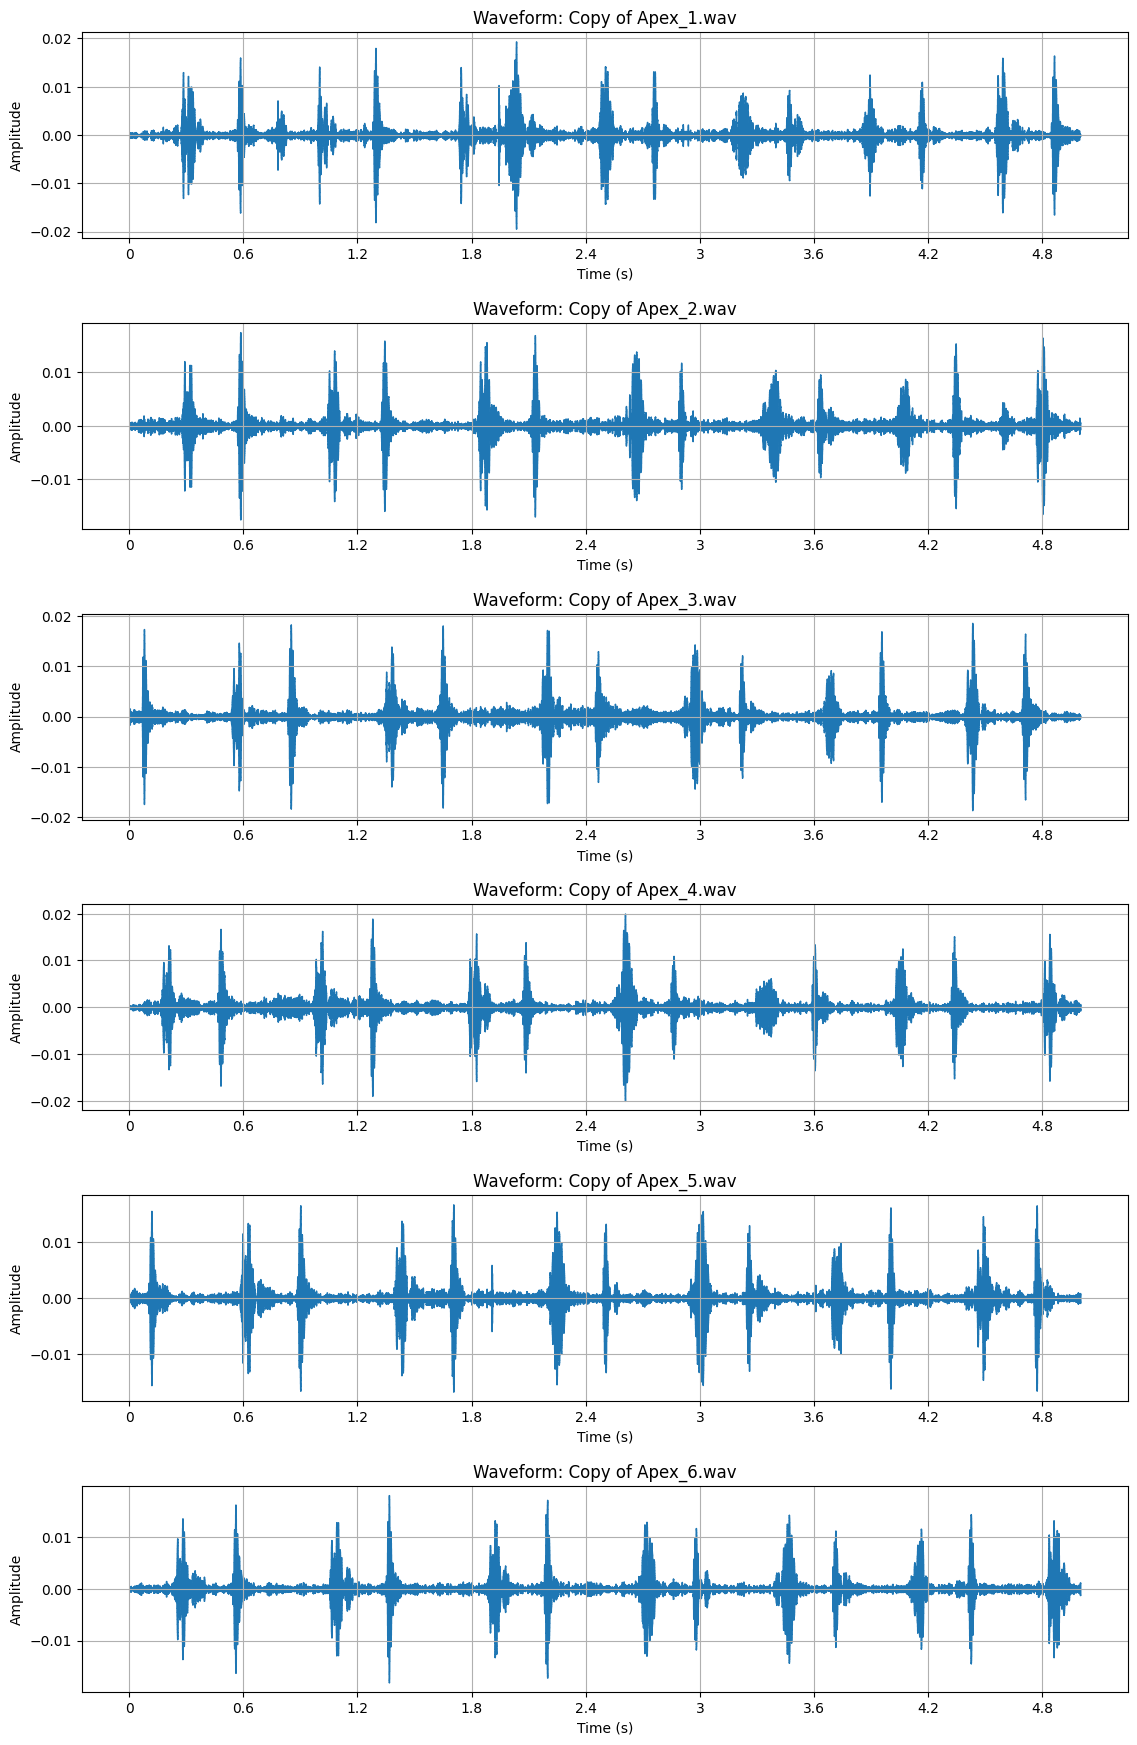

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os

output_dir = '/content/normal_segment'
base_name = "Copy of Apex"
num_segments = 6

fig, axes = plt.subplots(num_segments, 1, figsize=(12, 18))
fig.tight_layout(pad=4.0)

for i in range(num_segments):
    file_name = f"{base_name}_{i+1}.wav"
    file_path = os.path.join(output_dir, file_name)

    # Load the specific segment
    y_seg, sr_seg = librosa.load(file_path)

    # Plot the segment
    librosa.display.waveshow(y_seg, sr=sr_seg, ax=axes[i])
    axes[i].set_title(f"Waveform: {file_name}")
    axes[i].set_xlabel("Time (s)")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

plt.show()

In [ ]:
import os
import librosa
import soundfile as sf

# Paths
input_dir = '/content/drive/MyDrive/Research 2026/Data/Normal'
output_dir = '/content/normal_segment'
os.makedirs(output_dir, exist_ok=True)

segment_duration = 5

# Loop through every file in the input directory
for filename in os.listdir(input_dir):
    if filename.endswith('.wav'):
        file_path = os.path.join(input_dir, filename)
        base_name = os.path.splitext(filename)[0]

        # Load the audio file
        y, sr = librosa.load(file_path)
        duration = librosa.get_duration(y=y, sr=sr)

        # Calculate number of segments
        num_segments = int(np.ceil(duration / segment_duration))

        # Loop through segments and save them
        for i in range(num_segments):
            start_time = i * segment_duration
            end_time = min((i + 1) * segment_duration, duration)

            # Slice the audio array
            start_sample = int(start_time * sr)
            end_sample = int(end_time * sr)
            y_segment = y[start_sample:end_sample]

            # Define the output file name
            output_filename = f"{base_name}_{i+1}.wav"
            output_path = os.path.join(output_dir, output_filename)

            # Save the segment
            sf.write(output_path, y_segment, sr)
            print(f"Saved: {output_path}")

Saved: /content/normal_segment/Copy of Apex (7)_1.wav
Saved: /content/normal_segment/Copy of Apex (7)_2.wav
Saved: /content/normal_segment/Copy of Apex (7)_3.wav
Saved: /content/normal_segment/Copy of Apex (7)_4.wav
Saved: /content/normal_segment/Copy of Apex (7)_5.wav
Saved: /content/normal_segment/Copy of Apex (7)_6.wav
Saved: /content/normal_segment/Copy of Apex (9)_1.wav
Saved: /content/normal_segment/Copy of Apex (9)_2.wav
Saved: /content/normal_segment/Copy of Apex (9)_3.wav
Saved: /content/normal_segment/Copy of Apex (9)_4.wav
Saved: /content/normal_segment/Copy of Apex (9)_5.wav
Saved: /content/normal_segment/Copy of Apex (9)_6.wav
Saved: /content/normal_segment/Copy of Apex (3)_1.wav
Saved: /content/normal_segment/Copy of Apex (3)_2.wav
Saved: /content/normal_segment/Copy of Apex (3)_3.wav
Saved: /content/normal_segment/Copy of Apex (3)_4.wav
Saved: /content/normal_segment/Copy of Apex (3)_5.wav
Saved: /content/normal_segment/Copy of Apex (3)_6.wav
Saved: /content/normal_segme

In [ ]:
import os

path = '/content/normal_segment'
if os.path.exists(path):
    files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]
    print(f"Total files in '{path}': {len(files)}")
else:
    print(f"Directory '{path}' does not exist.")

Total files in '/content/normal_segment': 1675


In [ ]:
import os

# Source directory path
source_path = '/content/drive/MyDrive/Research 2026/Data/Normal'

if os.path.exists(source_path):
    source_files = [f for f in os.listdir(source_path) if f.endswith('.wav')]
    print(f"Total .wav files in source folder: {len(source_files)}")
else:
    print(f"Source directory '{source_path}' not found.")

Total .wav files in source folder: 280


In [ ]:
import os
from collections import Counter

# Get all segment filenames
segment_files = [f for f in os.listdir('/content/normal_segment') if f.endswith('.wav')]

# Extract the original base name by removing the '_n.wav' suffix
base_names = [f.rsplit('_', 1)[0] for f in segment_files]
counts = Counter(base_names)

# Find files that have fewer than 6 segments
less_than_six = {name: count for name, count in counts.items() if count < 6}

if less_than_six:
    print(f"Found {len(less_than_six)} files with fewer than 6 segments:")
    for name, count in less_than_six.items():
        print(f"- {name}: {count} segments")
else:
    print("All files produced exactly 6 segments (or more).")

Found 1 files with fewer than 6 segments:
- Copy of LLSB (47): 1 segments


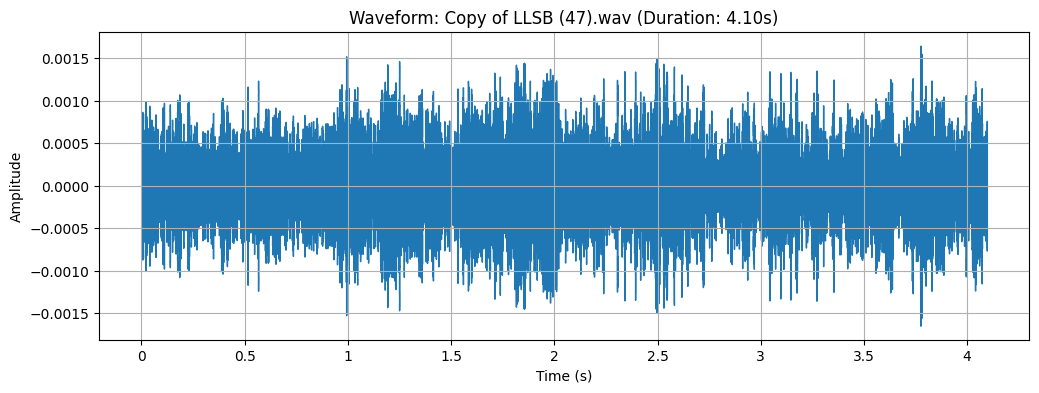

The total duration of this file is 4.10 seconds.


In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

# Path to the specific short file
short_file_path = '/content/drive/MyDrive/Research 2026/Data/Normal/Copy of LLSB (47).wav'

# Load the audio file
y_short, sr_short = librosa.load(short_file_path)
duration_short = librosa.get_duration(y=y_short, sr=sr_short)

# Plot the waveform
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y_short, sr=sr_short)
plt.title(f"Waveform: Copy of LLSB (47).wav (Duration: {duration_short:.2f}s)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

print(f"The total duration of this file is {duration_short:.2f} seconds.")

In [ ]:
import numpy as np
import soundfile as sf
import os

# Target parameters
target_duration = 30
segment_duration = 5
output_dir = '/content/normal_segment'
base_name = "Copy of LLSB (47)"

# 1. Augment by looping the audio to reach 30 seconds
# y_short and sr_short were loaded in the previous cell
num_repeats = int(np.ceil(target_duration / duration_short))
y_augmented = np.tile(y_short, num_repeats)

# Trim exactly to 30 seconds
target_samples = target_duration * sr_short
y_augmented = y_augmented[:target_samples]

print(f"Augmented length: {len(y_augmented)/sr_short:.2f} seconds")

# 2. Segment the augmented audio into 6 parts
for i in range(6):
    start_sample = i * segment_duration * sr_short
    end_sample = (i + 1) * segment_duration * sr_short
    y_segment = y_augmented[start_sample:end_sample]

    output_filename = f"{base_name}_{i+1}.wav"
    output_path = os.path.join(output_dir, output_filename)

    sf.write(output_path, y_segment, sr_short)
    print(f"Saved augmented segment: {output_path}")

Augmented length: 30.00 seconds
Saved augmented segment: /content/normal_segment/Copy of LLSB (47)_1.wav
Saved augmented segment: /content/normal_segment/Copy of LLSB (47)_2.wav
Saved augmented segment: /content/normal_segment/Copy of LLSB (47)_3.wav
Saved augmented segment: /content/normal_segment/Copy of LLSB (47)_4.wav
Saved augmented segment: /content/normal_segment/Copy of LLSB (47)_5.wav
Saved augmented segment: /content/normal_segment/Copy of LLSB (47)_6.wav


In [ ]:
# Verification: Check the total file count again
files = [f for f in os.listdir(output_dir) if os.path.isfile(os.path.join(output_dir, f))]
print(f"New total files in '{output_dir}': {len(files)}")
# Expected: 1675 + 5 new segments = 1680

New total files in '/content/normal_segment': 1680


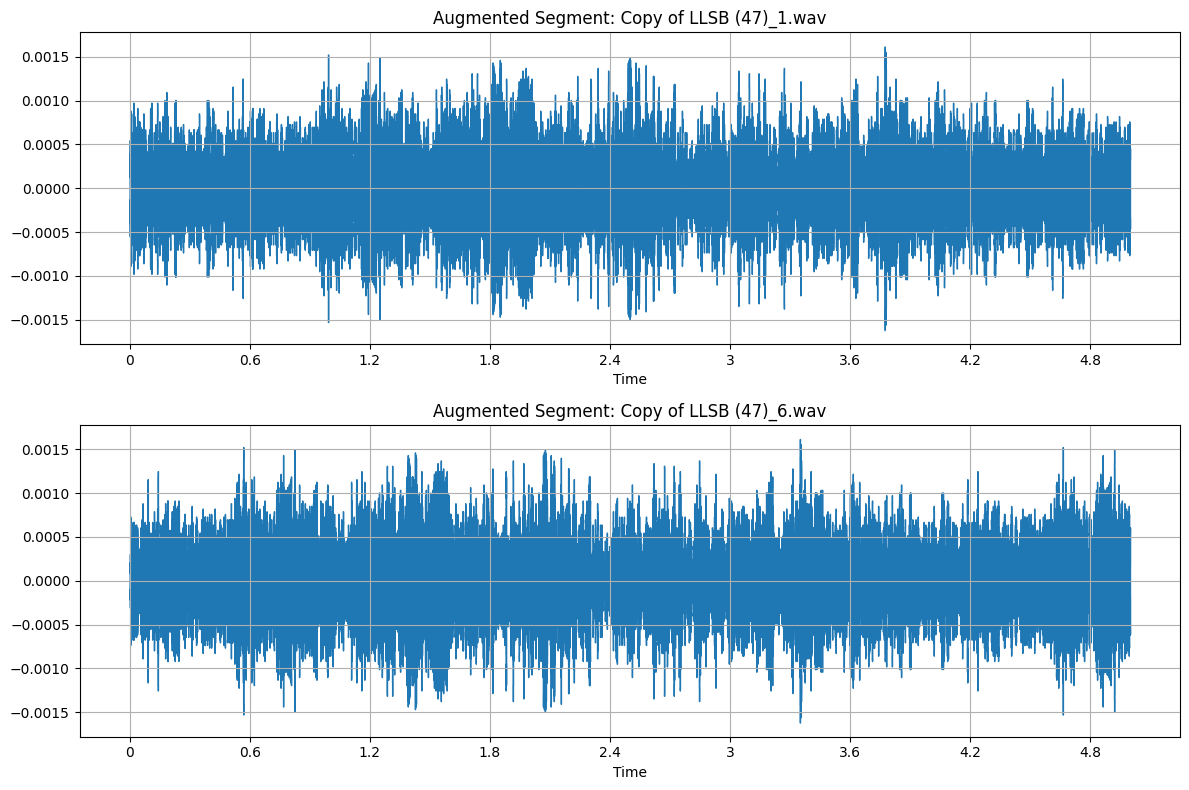

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os

# Visualize the first and last augmented segments to verify
aug_segments = ['Copy of LLSB (47)_1.wav', 'Copy of LLSB (47)_6.wav']
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for i, seg_name in enumerate(aug_segments):
    path = os.path.join('/content/normal_segment', seg_name)
    if os.path.exists(path):
        y_v, sr_v = librosa.load(path)
        librosa.display.waveshow(y_v, sr=sr_v, ax=axes[i])
        axes[i].set_title(f"Augmented Segment: {seg_name}")
        axes[i].grid(True)
    else:
        axes[i].set_title(f"File not found: {seg_name}")

plt.tight_layout()
plt.show()

In [ ]:
import os
import librosa
import soundfile as sf

# Paths
input_dir = '/content/drive/MyDrive/Research 2026/Data/Myocardial'
output_dir = '/content/myocardial_segment'
os.makedirs(output_dir, exist_ok=True)

segment_duration = 5

# Loop through every file in the input directory
for filename in os.listdir(input_dir):
    if filename.endswith('.wav'):
        file_path = os.path.join(input_dir, filename)
        base_name = os.path.splitext(filename)[0]

        # Load the audio file
        y, sr = librosa.load(file_path)
        duration = librosa.get_duration(y=y, sr=sr)

        # Calculate number of segments
        num_segments = int(np.ceil(duration / segment_duration))

        # Loop through segments and save them
        for i in range(num_segments):
            start_time = i * segment_duration
            end_time = min((i + 1) * segment_duration, duration)

            # Slice the audio array
            start_sample = int(start_time * sr)
            end_sample = int(end_time * sr)
            y_segment = y[start_sample:end_sample]

            # Define the output file name
            output_filename = f"{base_name}_{i+1}.wav"
            output_path = os.path.join(output_dir, output_filename)

            # Save the segment
            sf.write(output_path, y_segment, sr)
            print(f"Saved: {output_path}")

Saved: /content/myocardial_segment/Copy of Copy of Asep Rohendi_LUSB_16 Agustus 2022_1.wav
Saved: /content/myocardial_segment/Copy of Copy of Asep Rohendi_LUSB_16 Agustus 2022_2.wav
Saved: /content/myocardial_segment/Copy of Copy of Asep Rohendi_LUSB_16 Agustus 2022_3.wav
Saved: /content/myocardial_segment/Copy of Copy of Asep Rohendi_LUSB_16 Agustus 2022_4.wav
Saved: /content/myocardial_segment/Copy of Copy of Asep Rohendi_LUSB_16 Agustus 2022_5.wav
Saved: /content/myocardial_segment/Copy of Copy of Asep Rohendi_LUSB_16 Agustus 2022_6.wav
Saved: /content/myocardial_segment/Copy of Copy of Amat_RUSB_19 Mei 2022_1_1.wav
Saved: /content/myocardial_segment/Copy of Copy of Amat_RUSB_19 Mei 2022_1_2.wav
Saved: /content/myocardial_segment/Copy of Copy of Amat_RUSB_19 Mei 2022_1_3.wav
Saved: /content/myocardial_segment/Copy of Copy of Amat_RUSB_19 Mei 2022_1_4.wav
Saved: /content/myocardial_segment/Copy of Copy of Amat_RUSB_19 Mei 2022_1_5.wav
Saved: /content/myocardial_segment/Copy of Copy o

In [ ]:
import os

path = '/content/myocardial_segment'
if os.path.exists(path):
    files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]
    print(f"Total files in '{path}': {len(files)}")
else:
    print(f"Directory '{path}' does not exist.")

Total files in '/content/myocardial_segment': 1675


In [ ]:
import os
from collections import Counter

# Get all segment filenames
segment_files = [f for f in os.listdir('/content/myocardial_segment') if f.endswith('.wav')]

# Extract the original base name by removing the '_n.wav' suffix
base_names = [f.rsplit('_', 1)[0] for f in segment_files]
counts = Counter(base_names)

# Find files that have fewer than 6 segments
less_than_six = {name: count for name, count in counts.items() if count < 6}

if less_than_six:
    print(f"Found {len(less_than_six)} files with fewer than 6 segments:")
    for name, count in less_than_six.items():
        print(f"- {name}: {count} segments")
else:
    print("All files produced exactly 6 segments (or more).")

Found 2 files with fewer than 6 segments:
- Copy of Copy of Nur Hidayat_APEX_4 April 2022_1: 4 segments
- Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1: 3 segments


In [ ]:
import os
import librosa
import soundfile as sf
import numpy as np

# Configuration
input_dir = '/content/drive/MyDrive/Research 2026/Data/Myocardial'
output_dir = '/content/myocardial_segment'
target_duration = 30
segment_duration = 5

# The 2 files identified as short from cell rdl5QfiO_zR7
short_files = [
    'Copy of Copy of Nur Hidayat_APEX_4 April 2022_1.wav',
    'Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1.wav'
]

for filename in short_files:
    file_path = os.path.join(input_dir, filename)
    if not os.path.exists(file_path):
        print(f"Warning: Could not find {file_path}")
        continue

    base_name = os.path.splitext(filename)[0]

    # Load audio
    y, sr = librosa.load(file_path)
    duration = librosa.get_duration(y=y, sr=sr)

    # Augment by tiling (looping) the audio to reach at least 30s
    num_repeats = int(np.ceil(target_duration / duration))
    y_aug = np.tile(y, num_repeats)
    y_aug = y_aug[:int(target_duration * sr)]

    # Save the 6 segments (overwriting previous incomplete ones)
    for i in range(6):
        start = int(i * segment_duration * sr)
        end = int((i + 1) * segment_duration * sr)
        y_seg = y_aug[start:end]

        out_name = f"{base_name}_{i+1}.wav"
        out_path = os.path.join(output_dir, out_name)
        sf.write(out_path, y_seg, sr)
        print(f"Saved augmented segment: {out_name}")

print("Augmentation of short myocardial files complete.")

Saved augmented segment: Copy of Copy of Nur Hidayat_APEX_4 April 2022_1_1.wav
Saved augmented segment: Copy of Copy of Nur Hidayat_APEX_4 April 2022_1_2.wav
Saved augmented segment: Copy of Copy of Nur Hidayat_APEX_4 April 2022_1_3.wav
Saved augmented segment: Copy of Copy of Nur Hidayat_APEX_4 April 2022_1_4.wav
Saved augmented segment: Copy of Copy of Nur Hidayat_APEX_4 April 2022_1_5.wav
Saved augmented segment: Copy of Copy of Nur Hidayat_APEX_4 April 2022_1_6.wav
Saved augmented segment: Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1_1.wav
Saved augmented segment: Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1_2.wav
Saved augmented segment: Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1_3.wav
Saved augmented segment: Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1_4.wav
Saved augmented segment: Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1_5.wav
Saved augmented segment: Copy of Copy of Asep Redi Margana_APEX_27 Mei 2022_1_6.wav
Augmentation of short 

In [ ]:
import os

path = '/content/myocardial_segment'
if os.path.exists(path):
    files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]
    print(f"Total files in '{path}': {len(files)}")
else:
    print(f"Directory '{path}' does not exist.")

Total files in '/content/myocardial_segment': 1680


In [ ]:
!zip -r /content/myocardial_segments.zip /content/myocardial_segment
print("Zipping of myocardial_segment complete.")

  adding: content/myocardial_segment/ (stored 0%)
  adding: content/myocardial_segment/Copy of Copy of Andi Sudrajat_LUSB_14 Juli 2022_6.wav (deflated 79%)
  adding: content/myocardial_segment/Copy of Copy of Karsih._LLSB_20 Mei 2022_1.wav (deflated 65%)
  adding: content/myocardial_segment/Copy of Copy of Iwan Setiawan_RUSB_4 April 2022_1_6.wav (deflated 72%)
  adding: content/myocardial_segment/Copy of Copy of Epong_APEX_14 Juli 2022_4.wav (deflated 83%)
  adding: content/myocardial_segment/Copy of Copy of Suharyanto_APEX_26 Agustus 2022_5.wav (deflated 82%)
  adding: content/myocardial_segment/Copy of Copy of Iding_APEX_27 September 2022_6.wav (deflated 80%)
  adding: content/myocardial_segment/Copy of Copy of Herdiyanto_LLSB_25 Juli 2022_6.wav (deflated 74%)
  adding: content/myocardial_segment/Copy of Copy of Suharyanto_APEX_26 Agustus 2022_1.wav (deflated 83%)
  adding: content/myocardial_segment/Copy of Copy of Sadirman Tanjung_LUSB_29 Juni 2022_1.wav (deflated 80%)
  adding: co

In [ ]:
import os
import librosa
import soundfile as sf

# Paths
input_dir = '/content/drive/MyDrive/Research 2026/Data/STEMI'
output_dir = '/content/STEMI_segment'
os.makedirs(output_dir, exist_ok=True)

segment_duration = 5

# Loop through every file in the input directory
for filename in os.listdir(input_dir):
    if filename.endswith('.wav'):
        file_path = os.path.join(input_dir, filename)
        base_name = os.path.splitext(filename)[0]

        # Load the audio file
        y, sr = librosa.load(file_path)
        duration = librosa.get_duration(y=y, sr=sr)

        # Calculate number of segments
        num_segments = int(np.ceil(duration / segment_duration))

        # Loop through segments and save them
        for i in range(num_segments):
            start_time = i * segment_duration
            end_time = min((i + 1) * segment_duration, duration)

            # Slice the audio array
            start_sample = int(start_time * sr)
            end_sample = int(end_time * sr)
            y_segment = y[start_sample:end_sample]

            # Define the output file name
            output_filename = f"{base_name}_{i+1}.wav"
            output_path = os.path.join(output_dir, output_filename)

            # Save the segment
            sf.write(output_path, y_segment, sr)
            print(f"Saved: {output_path}")

Saved: /content/STEMI_segment/patient 1_Aan_apex_1.wav
Saved: /content/STEMI_segment/patient 1_Aan_apex_2.wav
Saved: /content/STEMI_segment/patient 1_Aan_apex_3.wav
Saved: /content/STEMI_segment/patient 1_Aan_apex_4.wav
Saved: /content/STEMI_segment/patient 1_Aan_apex_5.wav
Saved: /content/STEMI_segment/patient 1_Aan_apex_6.wav
Saved: /content/STEMI_segment/patient 1_Aan_llsb_1.wav
Saved: /content/STEMI_segment/patient 1_Aan_llsb_2.wav
Saved: /content/STEMI_segment/patient 1_Aan_llsb_3.wav
Saved: /content/STEMI_segment/patient 1_Aan_llsb_4.wav
Saved: /content/STEMI_segment/patient 1_Aan_llsb_5.wav
Saved: /content/STEMI_segment/patient 1_Aan_llsb_6.wav
Saved: /content/STEMI_segment/patient 1_Aan_lusb_1.wav
Saved: /content/STEMI_segment/patient 1_Aan_lusb_2.wav
Saved: /content/STEMI_segment/patient 1_Aan_lusb_3.wav
Saved: /content/STEMI_segment/patient 1_Aan_lusb_4.wav
Saved: /content/STEMI_segment/patient 1_Aan_lusb_5.wav
Saved: /content/STEMI_segment/patient 1_Aan_lusb_6.wav
Saved: /co

In [ ]:
import os

stemi_path = '/content/STEMI_segment'
if os.path.exists(stemi_path):
    stemi_files = [f for f in os.listdir(stemi_path) if os.path.isfile(os.path.join(stemi_path, f))]
    print(f"Total files in '{stemi_path}': {len(stemi_files)}")
else:
    print(f"Directory '{stemi_path}' does not exist.")

Total files in '/content/STEMI_segment': 1667


In [ ]:
import os
from collections import Counter

# 1. Count source files
stemi_source = '/content/drive/MyDrive/Research 2026/Data/STEMI'
if os.path.exists(stemi_source):
    source_wavs = [f for f in os.listdir(stemi_source) if f.endswith('.wav')]
    print(f"Total .wav files in STEMI source: {len(source_wavs)}")
    print(f"Expected segments (if all 30s): {len(source_wavs) * 6}")

# 2. Identify files with fewer than 6 segments
stemi_out = '/content/STEMI_segment'
segment_files = [f for f in os.listdir(stemi_out) if f.endswith('.wav')]
base_names = [f.rsplit('_', 1)[0] for f in segment_files]
counts = Counter(base_names)

less_than_six = {name: count for name, count in counts.items() if count < 6}

if less_than_six:
    print(f"\nFound {len(less_than_six)} files with fewer than 6 segments:")
    for name, count in sorted(less_than_six.items()):
        print(f"- {name}: {count} segments")
else:
    print("\nAll processed STEMI files produced at least 6 segments.")

Total .wav files in STEMI source: 280
Expected segments (if all 30s): 1680

Found 5 files with fewer than 6 segments:
- patient 20_Ahid Hidayat_apex: 3 segments
- patient 20_Ahid Hidayat_llsb: 3 segments
- patient 20_Ahid Hidayat_lusb: 3 segments
- patient 20_Ahid Hidayat_rusb: 3 segments
- patient 42_Asep Wawan Iskandar_llsb: 5 segments


In [ ]:
import librosa
import soundfile as sf
import numpy as np
import os

# Configuration
stemi_source_dir = '/content/drive/MyDrive/Research 2026/Data/STEMI'
stemi_output_dir = '/content/STEMI_segment'
target_duration = 30
segment_duration = 5

# The 5 files identified as short
short_files = [
    'patient 20_Ahid Hidayat_apex.wav',
    'patient 20_Ahid Hidayat_llsb.wav',
    'patient 20_Ahid Hidayat_lusb.wav',
    'patient 20_Ahid Hidayat_rusb.wav',
    'patient 42_Asep Wawan Iskandar_llsb.wav'
]

for filename in short_files:
    file_path = os.path.join(stemi_source_dir, filename)
    base_name = os.path.splitext(filename)[0]

    # Load audio
    y, sr = librosa.load(file_path)
    duration = librosa.get_duration(y=y, sr=sr)

    # Loop until at least 30 seconds
    num_repeats = int(np.ceil(target_duration / duration))
    y_aug = np.tile(y, num_repeats)
    y_aug = y_aug[:target_duration * sr]

    # Create all 6 segments (overwriting the previous incomplete ones)
    for i in range(6):
        start = i * segment_duration * sr
        end = (i + 1) * segment_duration * sr
        y_seg = y_aug[start:end]

        out_name = f"{base_name}_{i+1}.wav"
        out_path = os.path.join(stemi_output_dir, out_name)
        sf.write(out_path, y_seg, sr)

# Final Count Verification
final_count = len([f for f in os.listdir(stemi_output_dir) if f.endswith('.wav')])
print(f"Augmentation complete. Total STEMI segments: {final_count}")

Augmentation complete. Total STEMI segments: 1680


In [ ]:
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_features(file_path):
    try:
        # Using 'soxr_hq' or omitting res_type to avoid resampy dependency issues
        audio, sample_rate = librosa.load(file_path, sr=None)
        # Extract MFCCs
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        mfccs_processed = np.mean(mfccs.T, axis=0)
        return mfccs_processed
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

paths = {
    "Normal": "/content/drive/MyDrive/Research 2026/Segmented/normal_segment/",
    "STEMI": "/content/drive/MyDrive/Research 2026/Segmented/STEMI_segment"
}

features = []
labels = []

print("Extracting features...")
for label, path in paths.items():
    if not os.path.exists(path):
        continue
    file_list = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
    for file_name in file_list:
        file_path = os.path.join(path, file_name)
        data = extract_features(file_path)
        if data is not None:
            features.append(data)
            labels.append(label)

X = np.array(features)
y = np.array(labels)

if len(X) > 0:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"Final Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print(classification_report(y_test, y_pred))
else:
    print("No features were extracted. Check folder access.")

Extracting features...
Final Accuracy: 0.92
              precision    recall  f1-score   support

      Normal       0.94      0.90      0.92       357
       STEMI       0.89      0.93      0.91       315

    accuracy                           0.92       672
   macro avg       0.91      0.92      0.92       672
weighted avg       0.92      0.92      0.92       672



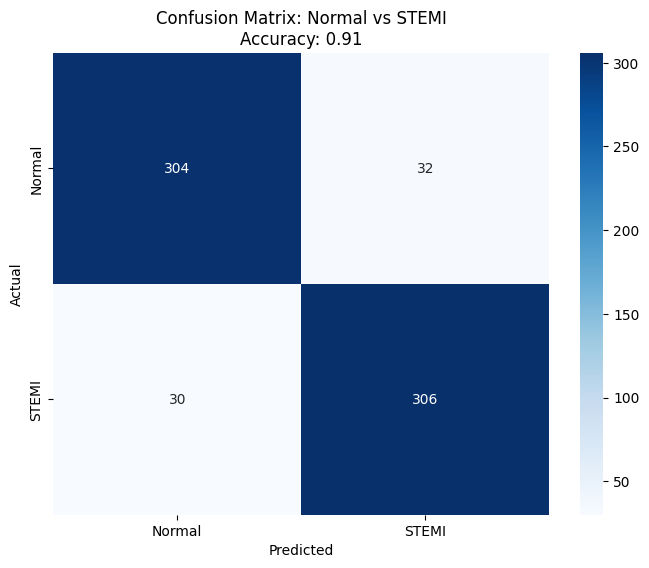

In [ ]:
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

def extract_features(file_path):
    try:
        audio, sample_rate = librosa.load(file_path, sr=2000)
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        return np.mean(mfccs.T, axis=0)
    except:
        return None

def get_data(labels_to_include):
    # Using correct local paths for segmented data
    paths = {
        "Normal": "/content/drive/MyDrive/Research 2026/Segmented/normal_segment/",
        "STEMI": "/content/drive/MyDrive/Research 2026/Segmented/STEMI_segment/"
    }
    X, y = [], []
    for label in labels_to_include:
        path = paths[label]
        if os.path.exists(path):
            files = [f for f in os.listdir(path) if f.endswith('.wav')]
            for f in files:
                feat = extract_features(os.path.join(path, f))
                if feat is not None:
                    X.append(feat)
                    y.append(label)
    return np.array(X), np.array(y)

# Load Data
X, y = get_data(["Normal", "STEMI"])

if len(X) > 0:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Plot Confusion Matrix
    labels = sorted(list(set(y)))
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(f'Confusion Matrix: Normal vs STEMI\nAccuracy: {accuracy_score(y_test, y_pred):.2f}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
else:
    print("No data found. Please ensure /content/normal_segment and /content/STEMI_segment exist.")

In [ ]:
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_features(file_path):
    try:
        # Set sample rate to 2000 Hz
        audio, sample_rate = librosa.load(file_path, sr=2000)
        # Extract MFCCs
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        mfccs_processed = np.mean(mfccs.T, axis=0)
        return mfccs_processed
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

paths = {
    "Normal": "/content/normal_segment/",
    "STEMI": "/content/STEMI_segment/"
}

features = []
labels = []

print("Extracting features with 2000 Hz sample rate...")
for label, path in paths.items():
    if not os.path.exists(path):
        continue
    file_list = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
    for file_name in file_list:
        file_path = os.path.join(path, file_name)
        data = extract_features(file_path)
        if data is not None:
            features.append(data)
            labels.append(label)

X = np.array(features)
y = np.array(labels)

if len(X) > 0:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"Final Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print(classification_report(y_test, y_pred))
else:
    print("No features were extracted. Check folder access.")

Extracting features with 2000 Hz sample rate...
Final Accuracy: 0.89
              precision    recall  f1-score   support

      Normal       0.90      0.89      0.90       357
       STEMI       0.88      0.89      0.88       315

    accuracy                           0.89       672
   macro avg       0.89      0.89      0.89       672
weighted avg       0.89      0.89      0.89       672



In [ ]:
import os

# Zip the STEMI segments
!zip -r /content/STEMI_segments.zip /content/STEMI_segment

# Zip the Normal segments
!zip -r /content/normal_segments.zip /content/normal_segment

print("Zipping complete.")

  adding: content/STEMI_segment/ (stored 0%)
  adding: content/STEMI_segment/patient 65_Dedi Rohaedi_rusb_1.wav (deflated 81%)
  adding: content/STEMI_segment/patient 38_Asep Redi Margana_rusb_4.wav (deflated 80%)
  adding: content/STEMI_segment/patient 50_Banaji_lusb_5.wav (deflated 74%)
  adding: content/STEMI_segment/patient 42_Asep Wawan Iskandar_llsb_1.wav (deflated 76%)
  adding: content/STEMI_segment/patient 50_Banaji_apex_2.wav (deflated 82%)
  adding: content/STEMI_segment/patient 34_Arif Rahman Setiawan_apex_3.wav (deflated 77%)
  adding: content/STEMI_segment/patient 68_Didit Supriatna_rusb_6.wav (deflated 77%)
  adding: content/STEMI_segment/patient 26_Ana Rosiana_rusb_4.wav (deflated 83%)
  adding: content/STEMI_segment/patient 33_Arief Permana Soetardjo_apex_1.wav (deflated 80%)
  adding: content/STEMI_segment/patient 40_Asep Rosidin_lusb_6.wav (deflated 73%)
  adding: content/STEMI_segment/patient 40_Asep Rosidin_rusb_1.wav (deflated 74%)
  adding: content/STEMI_segment/

In [ ]:
import os
import librosa
import soundfile as sf

# Paths
input_dir = '/content/drive/MyDrive/Research 2026/Data/NSTEMI'
output_dir = '/content/NSTEMI_segment'
os.makedirs(output_dir, exist_ok=True)

segment_duration = 5

# Loop through every file in the input directory
for filename in os.listdir(input_dir):
    if filename.endswith('.wav'):
        file_path = os.path.join(input_dir, filename)
        base_name = os.path.splitext(filename)[0]

        # Load the audio file
        y, sr = librosa.load(file_path)
        duration = librosa.get_duration(y=y, sr=sr)

        # Calculate number of segments
        num_segments = int(np.ceil(duration / segment_duration))

        # Loop through segments and save them
        for i in range(num_segments):
            start_time = i * segment_duration
            end_time = min((i + 1) * segment_duration, duration)

            # Slice the audio array
            start_sample = int(start_time * sr)
            end_sample = int(end_time * sr)
            y_segment = y[start_sample:end_sample]

            # Define the output file name
            output_filename = f"{base_name}_{i+1}.wav"
            output_path = os.path.join(output_dir, output_filename)

            # Save the segment
            sf.write(output_path, y_segment, sr)
            print(f"Saved: {output_path}")

Saved: /content/NSTEMI_segment/patient 1_Aang Diana_apex_1.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_apex_2.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_apex_3.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_apex_4.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_apex_5.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_apex_6.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_llsb_1.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_llsb_2.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_llsb_3.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_llsb_4.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_llsb_5.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_llsb_6.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_lusb_1.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_lusb_2.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_lusb_3.wav
Saved: /content/NSTEMI_segment/patient 1_Aang Diana_lus

In [ ]:
import os

path = '/content/NSTEMI_segment'
if os.path.exists(path):
    files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]
    print(f"Total files in '{path}': {len(files)}")
else:
    print(f"Directory '{path}' does not exist.")

Total files in '/content/NSTEMI_segment': 1680


In [ ]:
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Define the paths for STEMI and NSTEMI
paths = {
    "STEMI": "/content/STEMI_segment",
    "NSTEMI": "/content/NSTEMI_segment"
}

features_infarction = []
labels_infarction = []

print("Extracting features for STEMI vs NSTEMI classification...")

for label, path in paths.items():
    if not os.path.exists(path):
        print(f"Warning: Path not found {path}")
        continue

    file_list = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
    print(f"Processing {len(file_list)} files for {label}...")

    for file_name in file_list:
        file_path = os.path.join(path, file_name)
        # Re-using the extract_features function defined in previous cells
        data = extract_features(file_path)
        if data is not None:
            features_infarction.append(data)
            labels_infarction.append(label)

X_inf = np.array(features_infarction)
y_inf = np.array(labels_infarction)

if len(X_inf) > 0:
    # Split data
    X_train_inf, X_test_inf, y_train_inf, y_test_inf = train_test_split(
        X_inf, y_inf, test_size=0.2, random_state=42, stratify=y_inf
    )

    # Initialize and train model
    model_inf = RandomForestClassifier(n_estimators=100, random_state=42)
    model_inf.fit(X_train_inf, y_train_inf)

    # Evaluation
    y_pred_inf = model_inf.predict(X_test_inf)

    print("\n--- STEMI vs NSTEMI Classification Results ---")
    print(f"Accuracy: {accuracy_score(y_test_inf, y_pred_inf):.2f}")
    print(classification_report(y_test_inf, y_pred_inf))
else:
    print("Error: No features extracted. Please ensure the Drive is mounted and paths are correct.")

Extracting features for STEMI vs NSTEMI classification...
Processing 1680 files for STEMI...
Processing 1680 files for NSTEMI...

--- STEMI vs NSTEMI Classification Results ---
Accuracy: 0.76
              precision    recall  f1-score   support

      NSTEMI       0.75      0.78      0.77       336
       STEMI       0.77      0.74      0.76       336

    accuracy                           0.76       672
   macro avg       0.76      0.76      0.76       672
weighted avg       0.76      0.76      0.76       672



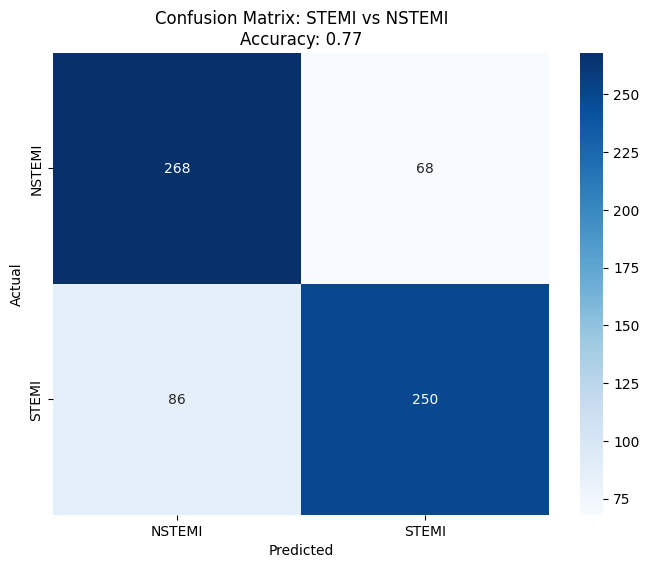

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# Define paths for STEMI and NSTEMI
paths = {
    "STEMI": "/content/drive/MyDrive/Research 2026/Segmented/STEMI_segment/",
    "NSTEMI": "/content/drive/MyDrive/Research 2026/Segmented/NSTEMI_segment/"
}

features_pairs = []
labels_pairs = []

# Extracting data for these two specific labels
for label, path in paths.items():
    if os.path.exists(path):
        file_list = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
        for file_name in file_list:
            file_path = os.path.join(path, file_name)
            data = extract_features(file_path)
            if data is not None:
                features_pairs.append(data)
                labels_pairs.append(label)

X_pair = np.array(features_pairs)
y_pair = np.array(labels_pairs)

if len(X_pair) > 0:
    # Split data
    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
        X_pair, y_pair, test_size=0.2, random_state=42, stratify=y_pair
    )

    # Train model
    model_p = RandomForestClassifier(n_estimators=100, random_state=42)
    model_p.fit(X_train_p, y_train_p)
    y_pred_p = model_p.predict(X_test_p)

    # Plot Confusion Matrix
    labels_list = sorted(list(set(y_pair)))
    cm_p = confusion_matrix(y_test_p, y_pred_p, labels=labels_list)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_p, annot=True, fmt='d', cmap='Blues', xticklabels=labels_list, yticklabels=labels_list)
    plt.title(f'Confusion Matrix: STEMI vs NSTEMI\nAccuracy: {accuracy_score(y_test_p, y_pred_p):.2f}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
else:
    print("Error: No data found in the specified paths.")

In [ ]:
import os
import numpy as np
import librosa
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_features(file_path):
    try:
        # Load audio with 2000 Hz sample rate
        audio, sample_rate = librosa.load(file_path, sr=2000)
        # Extract MFCCs
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        mfccs_processed = np.mean(mfccs.T, axis=0)
        return mfccs_processed
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

# Define the paths for STEMI and NSTEMI
paths = {
    "STEMI": "/content/STEMI_segment",
    "NSTEMI": "/content/NSTEMI_segment"
}

features_infarction = []
labels_infarction = []

print("Extracting features for STEMI vs NSTEMI classification (2000 Hz)...")

for label, path in paths.items():
    if not os.path.exists(path):
        print(f"Warning: Path not found {path}")
        continue

    file_list = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
    print(f"Processing {len(file_list)} files for {label}...")

    for file_name in file_list:
        file_path = os.path.join(path, file_name)
        data = extract_features(file_path)
        if data is not None:
            features_infarction.append(data)
            labels_infarction.append(label)

X_inf = np.array(features_infarction)
y_inf = np.array(labels_infarction)

if len(X_inf) > 0:
    # Split data
    X_train_inf, X_test_inf, y_train_inf, y_test_inf = train_test_split(
        X_inf, y_inf, test_size=0.2, random_state=42, stratify=y_inf
    )

    # Initialize and train model
    model_inf = RandomForestClassifier(n_estimators=100, random_state=42)
    model_inf.fit(X_train_inf, y_train_inf)

    # Evaluation
    y_pred_inf = model_inf.predict(X_test_inf)

    print("\n--- STEMI vs NSTEMI Classification Results (2000 Hz) ---")
    print(f"Accuracy: {accuracy_score(y_test_inf, y_pred_inf):.2f}")
    print(classification_report(y_test_inf, y_pred_inf))
else:
    print("Error: No features extracted. Please ensure the Drive is mounted and paths are correct.")

Extracting features for STEMI vs NSTEMI classification (2000 Hz)...
Processing 1680 files for STEMI...
Processing 1680 files for NSTEMI...

--- STEMI vs NSTEMI Classification Results (2000 Hz) ---
Accuracy: 0.76
              precision    recall  f1-score   support

      NSTEMI       0.75      0.78      0.77       336
       STEMI       0.77      0.74      0.76       336

    accuracy                           0.76       672
   macro avg       0.76      0.76      0.76       672
weighted avg       0.76      0.76      0.76       672



In [ ]:
import os
import librosa
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

def extract_features(file_path):
    try:
        # Using 'soxr_hq' or omitting res_type to avoid resampy dependency issues
        audio, sample_rate = librosa.load(file_path, sr=None)
        # Extract MFCCs
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        mfccs_processed = np.mean(mfccs.T, axis=0)
        return mfccs_processed
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

paths = {
    "Normal": "/content/normal_segment/",
    "STEMI": "/content/NSTEMI_segment/"
}

features = []
labels = []

print("Extracting features...")
for label, path in paths.items():
    if not os.path.exists(path):
        continue
    file_list = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
    for file_name in file_list:
        file_path = os.path.join(path, file_name)
        data = extract_features(file_path)
        if data is not None:
            features.append(data)
            labels.append(label)

X = np.array(features)
y = np.array(labels)

if len(X) > 0:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"Final Accuracy: {accuracy_score(y_test, y_pred):.2f}")
    print(classification_report(y_test, y_pred))
else:
    print("No features were extracted. Check folder access.")

Extracting features...
Final Accuracy: 0.91
              precision    recall  f1-score   support

      Normal       0.94      0.90      0.92       357
       STEMI       0.89      0.93      0.91       315

    accuracy                           0.91       672
   macro avg       0.91      0.91      0.91       672
weighted avg       0.91      0.91      0.91       672



Extracting features for Normal vs NSTEMI...


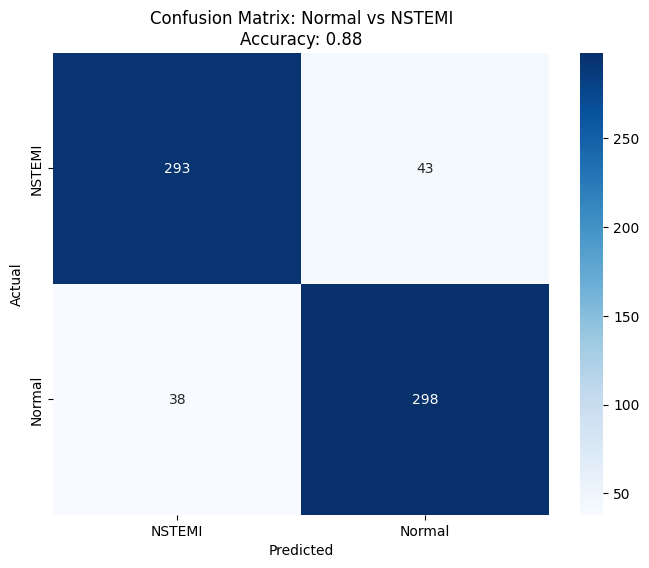

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# Define paths for Normal and NSTEMI
paths = {
    "Normal": "/content/drive/MyDrive/Research 2026/Segmented/normal_segment/",
    "NSTEMI": "/content/drive/MyDrive/Research 2026/Segmented/NSTEMI_segment/"
}

features_list = []
labels_list = []

print("Extracting features for Normal vs NSTEMI...")

for label, path in paths.items():
    if os.path.exists(path):
        files = [f for f in os.listdir(path) if f.lower().endswith('.wav')]
        for f in files:
            file_path = os.path.join(path, f)
            # extract_features is defined in previous cells
            feat = extract_features(file_path)
            if feat is not None:
                features_list.append(feat)
                labels_list.append(label)

X_n = np.array(features_list)
y_n = np.array(labels_list)

if len(X_n) > 0:
    X_train, X_test, y_train, y_test = train_test_split(X_n, y_n, test_size=0.2, random_state=42, stratify=y_n)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Plot Confusion Matrix
    unique_labels = sorted(list(set(y_n)))
    cm = confusion_matrix(y_test, y_pred, labels=unique_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=unique_labels, yticklabels=unique_labels)
    plt.title(f'Confusion Matrix: Normal vs NSTEMI\nAccuracy: {accuracy_score(y_test, y_pred):.2f}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()
else:
    print("Error: Data folders not found or empty.")

In [ ]:
!zip -r /content/NSTEMI_segments.zip /content/NSTEMI_segment
print("Zipping of NSTEMI segments complete.")

  adding: content/NSTEMI_segment/ (stored 0%)
  adding: content/NSTEMI_segment/patient 16_Ai Istiqomah_lusb_2.wav (deflated 81%)
  adding: content/NSTEMI_segment/patient 1_Aang Diana_rusb_1.wav (deflated 82%)
  adding: content/NSTEMI_segment/patient 10_Ade Sofian_lusb_6.wav (deflated 75%)
  adding: content/NSTEMI_segment/patient 70_Ijan Angkawidjaja_lusb_4.wav (deflated 68%)
  adding: content/NSTEMI_segment/patient 31_Badar Baraba_apex_2.wav (deflated 82%)
  adding: content/NSTEMI_segment/patient 3_Achmad Yani_lusb_5.wav (deflated 72%)
  adding: content/NSTEMI_segment/patient 32_Benny Bramasto_apex_6.wav (deflated 84%)
  adding: content/NSTEMI_segment/patient 41_Dedi Rosadi_lusb_2.wav (deflated 71%)
  adding: content/NSTEMI_segment/patient 28_Asep Saepuloh_apex_2.wav (deflated 85%)
  adding: content/NSTEMI_segment/patient 24_Asep Fadlillah_rusb_1.wav (deflated 64%)
  adding: content/NSTEMI_segment/patient 8_Ade Selamet_lusb_3.wav (deflated 79%)
  adding: content/NSTEMI_segment/patient 

In [ ]:
import os
import librosa
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

def extract_features(file_path):
    try:
        audio, sample_rate = librosa.load(file_path, sr=2000)
        mfccs = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
        return np.mean(mfccs.T, axis=0)
    except:
        return None

def get_data(labels_to_include):
    paths = {
        "Normal": "/content/normal_segment",
        "STEMI": "/content/STEMI_segment",
        "NSTEMI": "/content/NSTEMI_segment"
    }
    X, y = [], []
    for label in labels_to_include:
        path = paths[label]
        files = [f for f in os.listdir(path) if f.endswith('.wav')]
        for f in files:
            feat = extract_features(os.path.join(path, f))
            if feat is not None:
                X.append(feat)
                y.append(label)
    return np.array(X), np.array(y)

def plot_cm(X, y, title, ax):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    labels = sorted(list(set(y)))
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{title}\nAccuracy: {accuracy_score(y_test, y_pred):.2f}")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

print("Processing Normal vs STEMI...")
X1, y1 = get_data(["Normal", "STEMI"])
plot_cm(X1, y1, "Normal vs STEMI", axes[0])

print("Processing Normal vs NSTEMI...")
X2, y2 = get_data(["Normal", "NSTEMI"])
plot_cm(X2, y2, "Normal vs NSTEMI", axes[1])

print("Processing STEMI vs NSTEMI...")
X3, y3 = get_data(["STEMI", "NSTEMI"])
plot_cm(X3, y3, "STEMI vs NSTEMI", axes[2])

plt.tight_layout()
plt.show()